In [1]:
import pandas, numpy, scipy, re

In [2]:
import sklearn, sklearn.preprocessing, sklearn.decomposition

In [3]:
import matplotlib, matplotlib.pyplot
matplotlib.rcParams.update({'font.size':20, 
                            'font.family':'sans-serif', 
                            'xtick.labelsize':16, 
                            'ytick.labelsize':16, 
                            'figure.figsize':(16*(2/3), 9*(2/3)), 
                            'axes.labelsize':20
                           })

# 0. user-defined variables

In [4]:
input_file = '/Users/adrian/research/bmcbf/081/results/profiles/zebra/DESeq2_TPM_values.tsv'

# 1. read expression

In [5]:
expression = pandas.read_csv(input_file, sep='\t', index_col=0)
print(expression.shape)
expression

expression = expression.rename(columns={'ms_13G3_3': 'ms13G3_3'})

(27771, 12)


In [6]:
for element in expression.columns:
    print(element)

hSMOr173c_S1
hSMOr173c_S2
hSMOr173c_S3
hSMOwt_S1
hSMOwt_S3
hSMOwt_S4
KO_S1
KO_S2
KO_S3
WT_S1
WT_S2
WT_S3


# 3. filter and transform

In [7]:
groups = pandas.Series([re.sub(r'\d+$', '', c) for c in expression.columns],
                       index=expression.columns, name='group')

print(groups.index.to_series().groupby(groups.values).agg(list))   # check grouping

group_medians = expression.T.groupby(groups).median().T            # genes × conditions

substantial_expression = expression[group_medians.max(axis=1) >= 2]
high_expression        = expression[group_medians.max(axis=1) >= 100]
print(substantial_expression.shape, high_expression.shape)

KO_S                                [KO_S1, KO_S2, KO_S3]
WT_S                                [WT_S1, WT_S2, WT_S3]
hSMOr173c_S    [hSMOr173c_S1, hSMOr173c_S2, hSMOr173c_S3]
hSMOwt_S                [hSMOwt_S1, hSMOwt_S3, hSMOwt_S4]
dtype: object
(16791, 12) (1133, 12)


In [8]:
group_medians

group,KO_S,WT_S,hSMOr173c_S,hSMOwt_S
ENSDARG00000000001.6,2.049859,1.585854,2.287488,2.659998
ENSDARG00000000002.8,6.083760,4.950690,7.746126,7.497375
ENSDARG00000000018.9,16.209980,17.796115,17.610784,16.687846
ENSDARG00000000019.9,35.776412,38.770816,51.874070,50.561641
ENSDARG00000000068.9,13.602490,20.349374,22.757069,22.778026
...,...,...,...,...
ENSDARG00000117823.1,0.570929,0.000000,0.531799,0.000000
ENSDARG00000117824.1,2.655380,2.750925,5.122740,5.975533
ENSDARG00000117825.1,0.000000,0.000000,0.000000,0.000000
ENSDARG00000117826.1,0.096271,0.105184,0.146046,0.000000


In [9]:
transpose = substantial_expression.transpose()
pca_substantial_expression = numpy.log2(transpose + 1)

transpose = high_expression.transpose()
pca_high_expression = numpy.log2(transpose + 1)

# 4. visualize substantial expression

In [10]:
scaled_data = sklearn.preprocessing.StandardScaler().fit_transform(pca_substantial_expression)
model = sklearn.decomposition.PCA(n_components=2)
new = model.fit_transform(scaled_data)
explained = model.explained_variance_ratio_
print(explained)

[0.51203733 0.20448221]


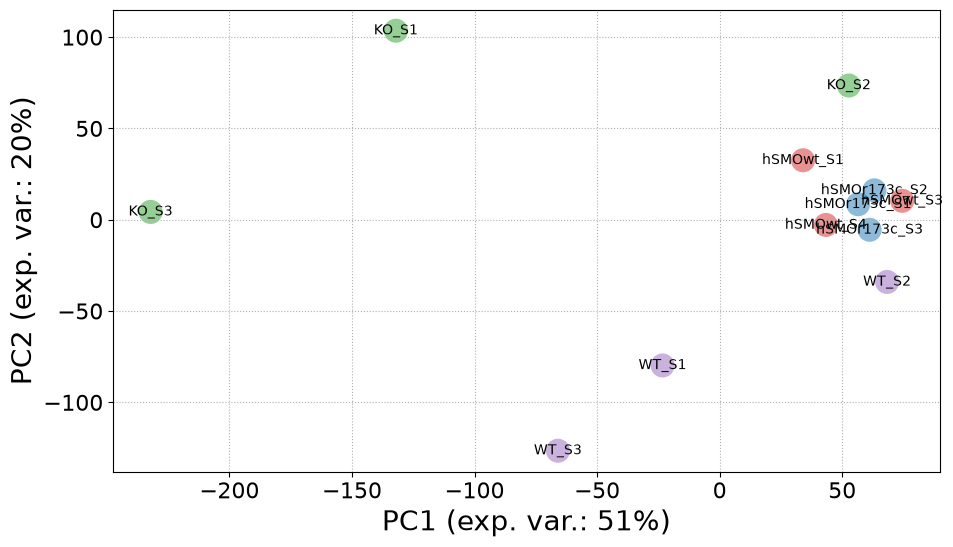

In [15]:
for i in range(len(new)):

    name = pca_substantial_expression.index[i]

    # colors
    if 'hSMOr173' in name:
        the_color = 'tab:blue'
    elif 'hSMOwt' in name:
        the_color = 'tab:red'
    elif 'KO' in name:
        the_color = 'tab:green'
    elif 'WT' in name:
        the_color = 'tab:purple'
    else:
        print('error')
    
    matplotlib.pyplot.scatter(new[i,0], new[i,1], s=300, c=the_color, marker='o', alpha=0.5, edgecolors='none')
    epsilon=0; matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=10, va='center', ha='center', alpha=1)


    legend_elements = [
        matplotlib.lines.Line2D([], [], marker='o', linestyle='none', markersize=16, markerfacecolor='white', markeredgecolor='black'),
        matplotlib.lines.Line2D([], [], marker='s', linestyle='none', markersize=16, markerfacecolor='white', markeredgecolor='black'),
        matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='black',    edgecolor='white', alpha=2/3),
        matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:blue',    edgecolor='white', alpha=2/3),
        matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:red',    edgecolor='white', alpha=2/3),
]    
    #matplotlib.pyplot.legend(legend_elements, ['AEG13', 'AEG14', 'DMSO', 'AZM', 'EP317'], 
    #                         ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))
    
matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()

In [12]:
# distributions

In [13]:
log2_tpm_PO = numpy.log2(expression + 1)
log2_tpm_PO.head()

,hSMOr173c_S1,hSMOr173c_S2,hSMOr173c_S3,hSMOwt_S1,hSMOwt_S3,hSMOwt_S4,KO_S1,KO_S2,KO_S3,WT_S1,WT_S2,WT_S3
ENSDARG00000000001.6,1.964666,1.716986,1.707338,2.055780,1.871843,1.748815,1.728467,1.608743,1.445528,1.370641,1.682863,1.273655
ENSDARG00000000002.8,3.128644,3.322590,2.877247,3.445379,3.087017,2.789334,2.824515,3.587607,2.206403,2.573057,2.807058,2.492801
ENSDARG00000000018.9,4.218067,4.193412,4.276464,4.020184,4.157469,4.144686,4.529688,4.105174,3.746041,4.232363,4.528725,4.136673
ENSDARG00000000019.9,5.920930,5.724488,5.704179,5.688226,5.875756,5.679151,5.200709,5.528996,4.404384,5.313638,5.874140,5.215664
ENSDARG00000000068.9,4.570285,4.571009,4.530431,4.571557,4.672217,4.337670,3.868143,4.550178,3.759839,4.416122,4.526397,4.054013


14.744426348448762


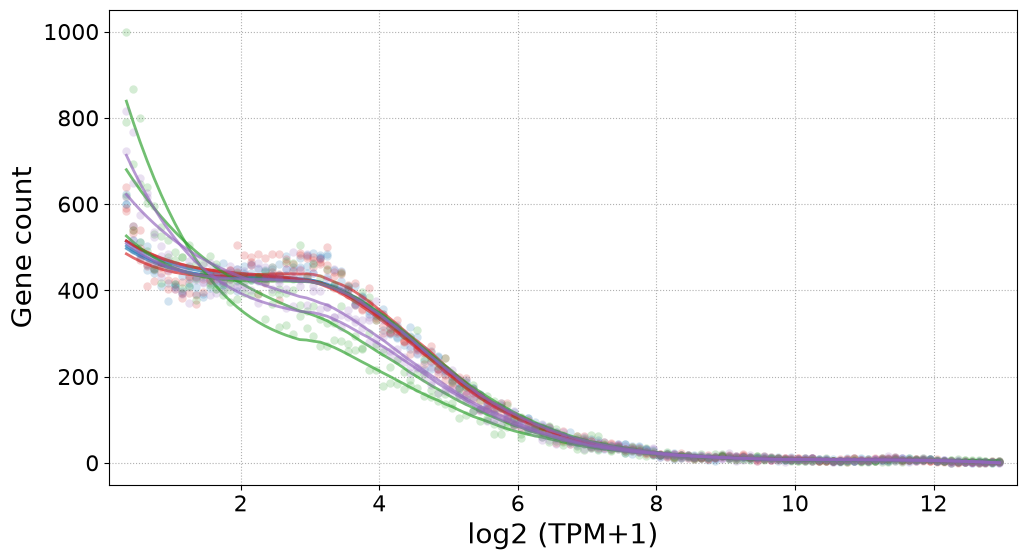

In [16]:
found_max = 17
number_of_bins = int(found_max*10)

absolute_max = 0
working_samples = log2_tpm_PO.columns.to_list()

most_likely_expressions = []
all_hats = []
for i in range(len(working_samples)):

    name = working_samples[i]

    # colors
    if 'hSMOr173' in name:
        the_color = 'tab:blue'
    elif 'hSMOwt' in name:
        the_color = 'tab:red'
    elif 'KO' in name:
        the_color = 'tab:green'
    elif 'WT' in name:
        the_color = 'tab:purple'
    else:
        print('error')

    
    log2TPM = log2_tpm_PO.loc[:, name]
    if max(log2TPM) > absolute_max:
        absolute_max = max(log2TPM)
                
    hist, bin_edges = numpy.histogram(log2TPM, bins=number_of_bins, range=(0, found_max))
    half_bin = (bin_edges[1] - bin_edges[0])/2
    x = bin_edges + half_bin
    x = x[:-1]
  
    plotting_x = x[3:-40]
    plotting_hist = hist[3:-40]
    #print(plotting_x)
    
    matplotlib.pyplot.plot(plotting_x, plotting_hist, 'o', alpha=1/5, mec='none', color=the_color)
    yhat = scipy.signal.savgol_filter(plotting_hist, 51, 3)

    matplotlib.pyplot.plot(plotting_x, yhat, '-', lw=2, alpha=2/3, color=the_color)
    
matplotlib.pyplot.xlim([numpy.min(plotting_x)-0.25, numpy.max(plotting_x)+0.25])

#matplotlib.pyplot.legend(legend_elements, ['Day 0', 'Day 7', 'Day 15', 'Day 21', 'Day 28', 'Day 35'], ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))

#legend_elements = [
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='black',      edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:blue',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='gold',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:orange',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:red',    edgecolor='white', alpha=2/3),
#    matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:purple',    edgecolor='white', alpha=2/3),
#]    

matplotlib.pyplot.xlabel('log2 (TPM+1)')
matplotlib.pyplot.ylabel('Gene count')
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.tight_layout()

print(absolute_max)